# Session 12: Data Visualization with Seaborn (Part 1)

**Module:** Data Collection, Cleaning, Visualization and Analysis  
**Session:** 12  
**Format:** Jupyter Notebook (`.ipynb`)  
**Core Libraries:** `seaborn`, `matplotlib`, `pandas`, `numpy`

---

## 🎯 Topics Covered
1. **Introduction to Seaborn**:
   - Statistical data visualization built on top of Matplotlib
   - Integration with Pandas DataFrames and semantic mapping (`x`, `y`, `hue`, `style`, `size`)
2. **Axes-Level vs. Figure-Level APIs**:
   - Axes-level (`sns.histplot`, `sns.kdeplot`, `sns.boxplot`, `sns.violinplot`, `sns.countplot`) returning `matplotlib.axes.Axes`
   - Figure-level functions (`sns.displot`, `sns.catplot`, `sns.relplot`) returning `FacetGrid`
3. **Distribution Plots**:
   - `sns.histplot()` with kernel density estimation (`kde=True`)
   - `sns.kdeplot()` for smooth continuous probability density functions
   - Legacy `distplot` context and modern Seaborn v0.11+ replacements
4. **Categorical Plots**:
   - `sns.boxplot()` for five-number summary and outlier diagnostics
   - `sns.violinplot()` for combining boxplot medians with kernel density distributions
   - `sns.countplot()` for categorical frequencies
5. **Styling & Themes**:
   - Built-in Seaborn themes: `'darkgrid'`, `'whitegrid'`, `'dark'`, `'white'`, `'ticks'`
   - Palette customization, color palettes (`'Spectral'`, `'viridis'`, `'Set2'`), and `sns.despine()`


---
### Task 1: Zomato Delivery Times Distribution (Histplot)
**Problem Statement:**  
*Install Seaborn in your Python environment and use it to create a `histplot` showing the distribution of delivery times (in minutes) for 50 Zomato food orders. Generate random data if needed.*


Seaborn Version: 0.13.2
Matplotlib Version: 3.10.0
Pandas Version: 2.3.3

--- Zomato Delivery Times Sample (Head & Summary) ---


,order_id,restaurant_name,delivery_time_mins,distance_km
0,ZOM-1001,Bikanervala,36.7,6.30
1,ZOM-1002,Chai Point,32.6,6.24
2,ZOM-1003,Chai Point,37.7,6.10
3,ZOM-1004,Bikanervala,43.4,7.11
4,ZOM-1005,Bikanervala,32.0,5.96
5,ZOM-1006,Bikanervala,32.0,5.28
6,ZOM-1007,Bikanervala,43.8,6.73
7,ZOM-1008,Domino's Pizza,38.5,6.27


,count,mean,std,min,25%,50%,75%,max
delivery_time_mins,50.0,32.028,6.064384,20.8,27.9,32.0,35.65,45.5


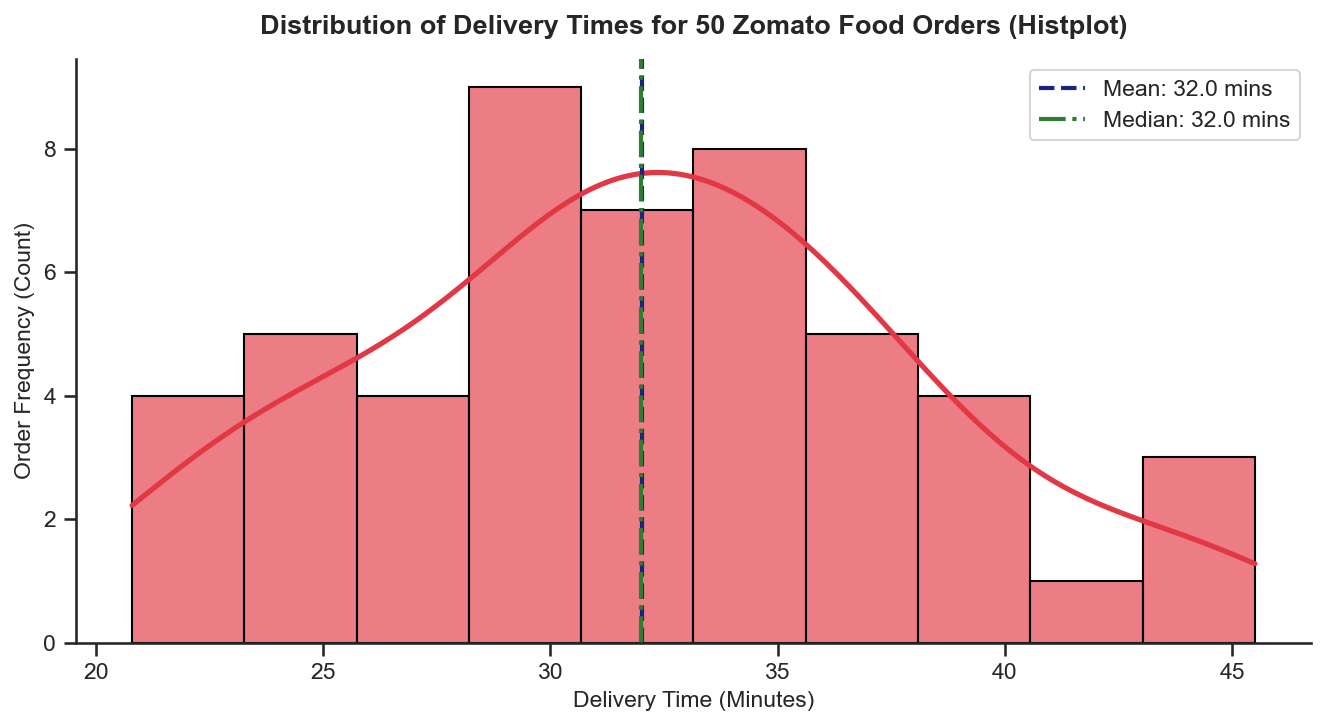

Mean Delivery Time: 32.03 mins
Median Delivery Time: 32.00 mins
IQR (Middle 50% Deliveries): 27.9 to 35.7 mins


In [1]:
# Verify Seaborn installation and environment
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print(f"Seaborn Version: {sns.__version__}")
print(f"Matplotlib Version: {plt.matplotlib.__version__}")
print(f"Pandas Version: {pd.__version__}")

# Load 50 Zomato food delivery records
df_deliv = pd.read_csv("zomato_delivery_times.csv")
print("\n--- Zomato Delivery Times Sample (Head & Summary) ---")
display(df_deliv.head(8))
display(df_deliv["delivery_time_mins"].describe().to_frame().T)

# Plotting Delivery Time Distribution using sns.histplot
plt.figure(figsize=(9, 5), dpi=150)
sns.set_theme(style="ticks")

ax = sns.histplot(
    data=df_deliv,
    x="delivery_time_mins",
    kde=True,
    bins=10,
    color="#E23744", # Zomato brand red
    edgecolor="black",
    alpha=0.65,
    line_kws={"linewidth": 2.5, "color": "#880E4F"}
)

# Reference benchmark lines
mean_val = df_deliv["delivery_time_mins"].mean()
median_val = df_deliv["delivery_time_mins"].median()

plt.axvline(mean_val, color="#1A237E", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.1f} mins")
plt.axvline(median_val, color="#2E7D32", linestyle="-.", linewidth=2, label=f"Median: {median_val:.1f} mins")

plt.title("Distribution of Delivery Times for 50 Zomato Food Orders (Histplot)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Delivery Time (Minutes)", fontsize=11)
plt.ylabel("Order Frequency (Count)", fontsize=11)
plt.legend(loc="upper right", frameon=True)
sns.despine()
plt.tight_layout()
plt.savefig("zomato_delivery_histplot.png", bbox_inches="tight")
plt.show()

print(f"Mean Delivery Time: {mean_val:.2f} mins")
print(f"Median Delivery Time: {median_val:.2f} mins")
print(f"IQR (Middle 50% Deliveries): {df_deliv['delivery_time_mins'].quantile(0.25):.1f} to {df_deliv['delivery_time_mins'].quantile(0.75):.1f} mins")


---
### Task 2: Spending Patterns Across Days of the Week (Boxplot)
**Problem Statement:**  
*Load the 'tips' dataset from Seaborn and create a `boxplot` to visualize the distribution of total bill amounts by day of the week, similar to how Zomato might analyze spending patterns across weekdays.*


--- Seaborn 'tips' Dataset Overview ---


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4


Total Rows: 244 | Days recorded: ['Sun', 'Sat', 'Thur', 'Fri']

--- Spending Statistics per Day ---


,count,mean,median,std,iqr
day,,,,,
Thur,62,17.682742,16.20,7.886170,7.7125
Fri,19,17.151579,15.38,8.302660,9.6550
Sat,87,20.441379,18.24,9.480419,10.8350
Sun,76,21.410000,19.63,8.832122,10.6100


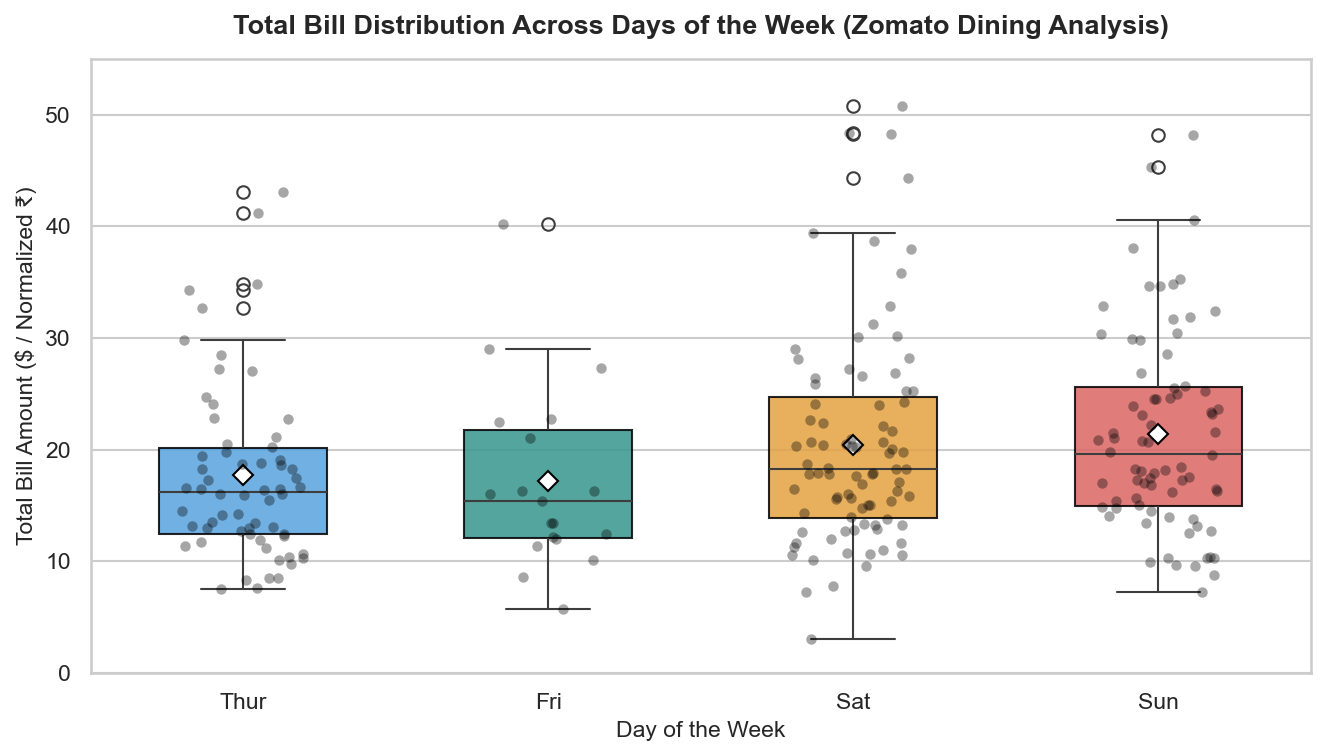

Key Insights: Weekend dining (Sat & Sun) displays significantly higher medians and upper outliers ($40-$50+), indicating higher group order sizes compared to workday lunches (Thur).


In [2]:
# Ingest Seaborn 'tips' dataset (fallback to saved tips.csv if offline)
try:
    df_tips = sns.load_dataset("tips")
except Exception:
    df_tips = pd.read_csv("tips.csv")

print("--- Seaborn 'tips' Dataset Overview ---")
display(df_tips.head(6))
print(f"Total Rows: {len(df_tips)} | Days recorded: {list(df_tips['day'].unique())}")

# Summary statistics grouped by day
day_summary = df_tips.groupby("day", observed=True)["total_bill"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
)
print("\n--- Spending Statistics per Day ---")
display(day_summary)

# Visualizing bill distribution with sns.boxplot
plt.figure(figsize=(9, 5.2), dpi=150)
sns.set_theme(style="whitegrid")

days_order = ["Thur", "Fri", "Sat", "Sun"]
palette_days = {"Thur": "#42A5F5", "Fri": "#26A69A", "Sat": "#FFA726", "Sun": "#EF5350"}

ax = sns.boxplot(
    data=df_tips,
    x="day",
    y="total_bill",
    hue="day",
    order=days_order,
    palette=palette_days,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": "7"},
    width=0.55,
    boxprops=dict(alpha=0.85, edgecolor="black"),
    legend=False
)

# Overlay stripplot with jitter for raw order points
sns.stripplot(
    data=df_tips,
    x="day",
    y="total_bill",
    order=days_order,
    color="black",
    alpha=0.35,
    size=5,
    jitter=0.2
)

plt.title("Total Bill Distribution Across Days of the Week (Zomato Dining Analysis)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Day of the Week", fontsize=11)
plt.ylabel("Total Bill Amount ($ / Normalized ₹)", fontsize=11)
plt.ylim(0, 55)
plt.tight_layout()
plt.savefig("total_bill_boxplot.png", bbox_inches="tight")
plt.show()

print("Key Insights: Weekend dining (Sat & Sun) displays significantly higher medians and upper outliers ($40-$50+), indicating higher group order sizes compared to workday lunches (Thur).")


---
### Task 3: IPL Match Score Distributions per Team (Violinplot - Darkgrid Theme)
**Problem Statement:**  
*Simulate IPL match scores for 8 teams and use a `violinplot` to compare the run distributions per team. Style your plot using the 'darkgrid' Seaborn theme.*


--- IPL Team Match Scores Dataset ---


,team,match_no,total_runs,wickets
0,CSK,1,182,5
1,CSK,2,175,4
2,CSK,3,192,5
3,CSK,4,150,9
4,CSK,5,158,5
5,CSK,6,192,6
6,CSK,7,157,10
7,CSK,8,205,9


Total Matches Simulated: 120 across 8 franchise teams

--- Team Scoring Performance Metrics ---


,count,mean,median,min,max,std
team,,,,,,
CSK,15,181.9,182.0,150,213,21.2
DC,15,175.9,173.0,143,208,19.0
KKR,15,177.5,176.0,133,228,21.1
MI,15,187.1,189.0,159,227,17.3
PK,15,176.3,181.0,120,220,22.9
RCB,15,198.0,201.0,155,241,27.1
RR,15,177.8,181.0,135,224,26.3
SRH,15,197.7,191.0,146,263,35.5


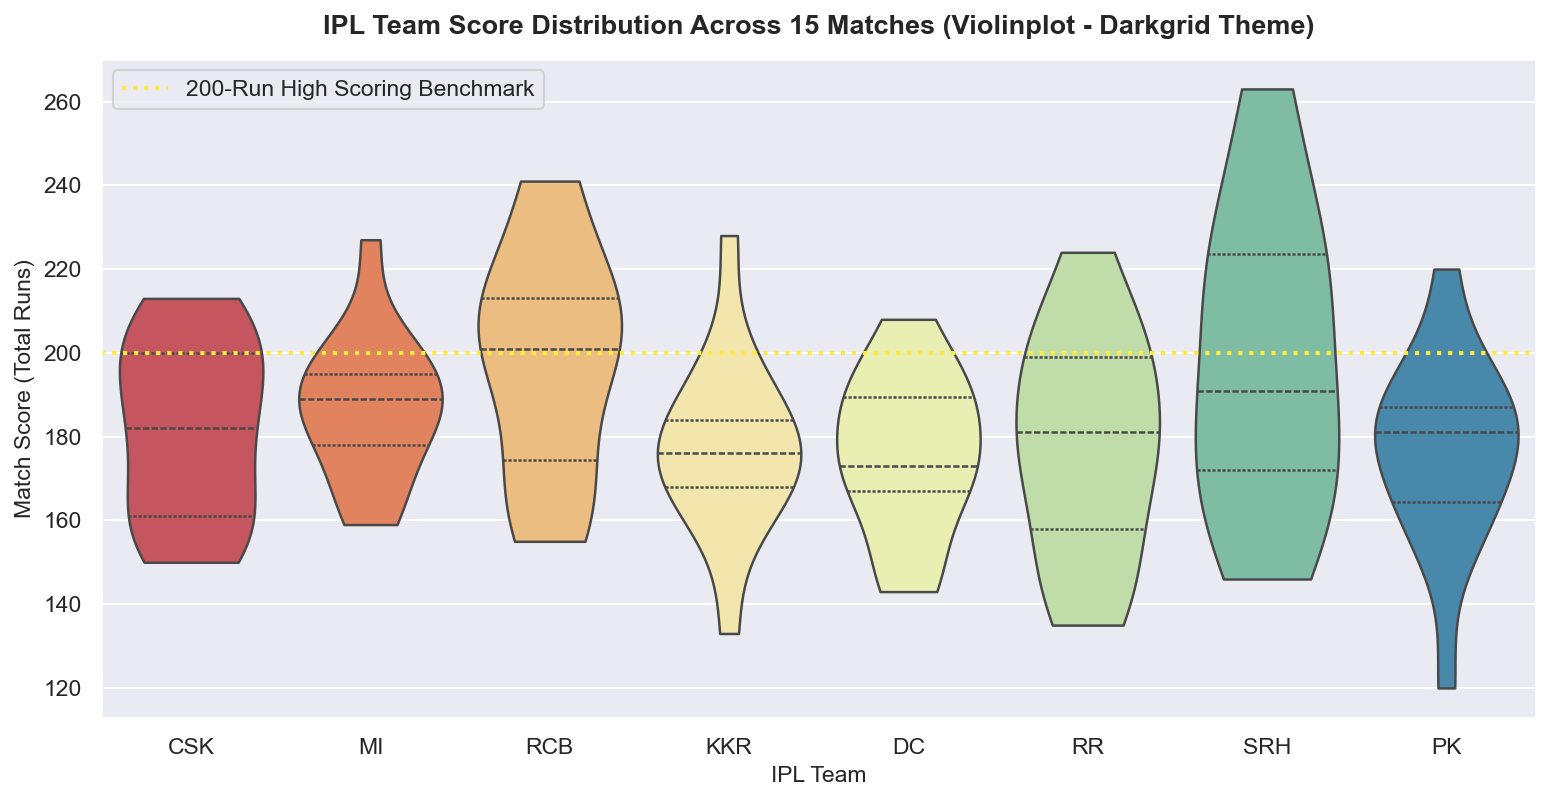

Key Insights: SRH and RCB display wider probability densities in the 200+ run range, reflecting explosive batting templates, while DC and KKR display tighter run clusters centered around 165-175 runs.


In [3]:
# Load simulated IPL match score dataset
df_ipl = pd.read_csv("ipl_team_scores.csv")
print("--- IPL Team Match Scores Dataset ---")
display(df_ipl.head(8))
print(f"Total Matches Simulated: {len(df_ipl)} across {df_ipl['team'].nunique()} franchise teams")

# Team statistical metrics
team_perf = df_ipl.groupby("team")["total_runs"].agg(["count", "mean", "median", "min", "max", "std"]).round(1)
print("\n--- Team Scoring Performance Metrics ---")
display(team_perf)

# Violinplot using 'darkgrid' theme
plt.figure(figsize=(10.5, 5.5), dpi=150)
sns.set_theme(style="darkgrid")

teams_order = ["CSK", "MI", "RCB", "KKR", "DC", "RR", "SRH", "PK"]

ax = sns.violinplot(
    data=df_ipl,
    x="team",
    y="total_runs",
    hue="team",
    order=teams_order,
    palette="Spectral",
    inner="quartile",
    cut=0,
    linewidth=1.2,
    legend=False
)

plt.axhline(200, color="#FFEB3B", linestyle=":", linewidth=2, label="200-Run High Scoring Benchmark")
plt.title("IPL Team Score Distribution Across 15 Matches (Violinplot - Darkgrid Theme)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("IPL Team", fontsize=11)
plt.ylabel("Match Score (Total Runs)", fontsize=11)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("ipl_scores_violinplot.png", bbox_inches="tight")
plt.show()

print("Key Insights: SRH and RCB display wider probability densities in the 200+ run range, reflecting explosive batting templates, while DC and KKR display tighter run clusters centered around 165-175 runs.")


---
### Task 4: Spotify Songs per Genre Distribution (Countplot)
**Problem Statement:**  
*Create a `countplot` that displays the number of songs per genre from a list of 40 Spotify tracks, with at least 4 different genres represented.*  
*Hint: Use a Python list or pandas DataFrame to store your data, then plot with Seaborn.*


--- 40 Spotify Tracks Dataset Sample ---


,track_name,genre,artist,duration_mins
0,Blinding Lights,Pop,The Weeknd,3.33
1,Levitating,Pop,Dua Lipa,3.38
2,As It Was,Pop,Harry Styles,2.78
3,Shape of You,Pop,Ed Sheeran,3.89
4,Starboy,Pop,The Weeknd,3.84
5,Stay,Pop,The Kid LAROI,2.36
6,Bad Guy,Pop,Billie Eilish,3.23
7,Watermelon Sugar,Pop,Harry Styles,2.90
8,HUMBLE.,Hip-Hop,Kendrick Lamar,2.95
9,God's Plan,Hip-Hop,Drake,3.31


Total Tracks: 40 across 5 distinct genres


,genre,track_count
0,Bollywood,10
1,Pop,8
2,Hip-Hop,8
3,Indie Rock,7
4,EDM,7


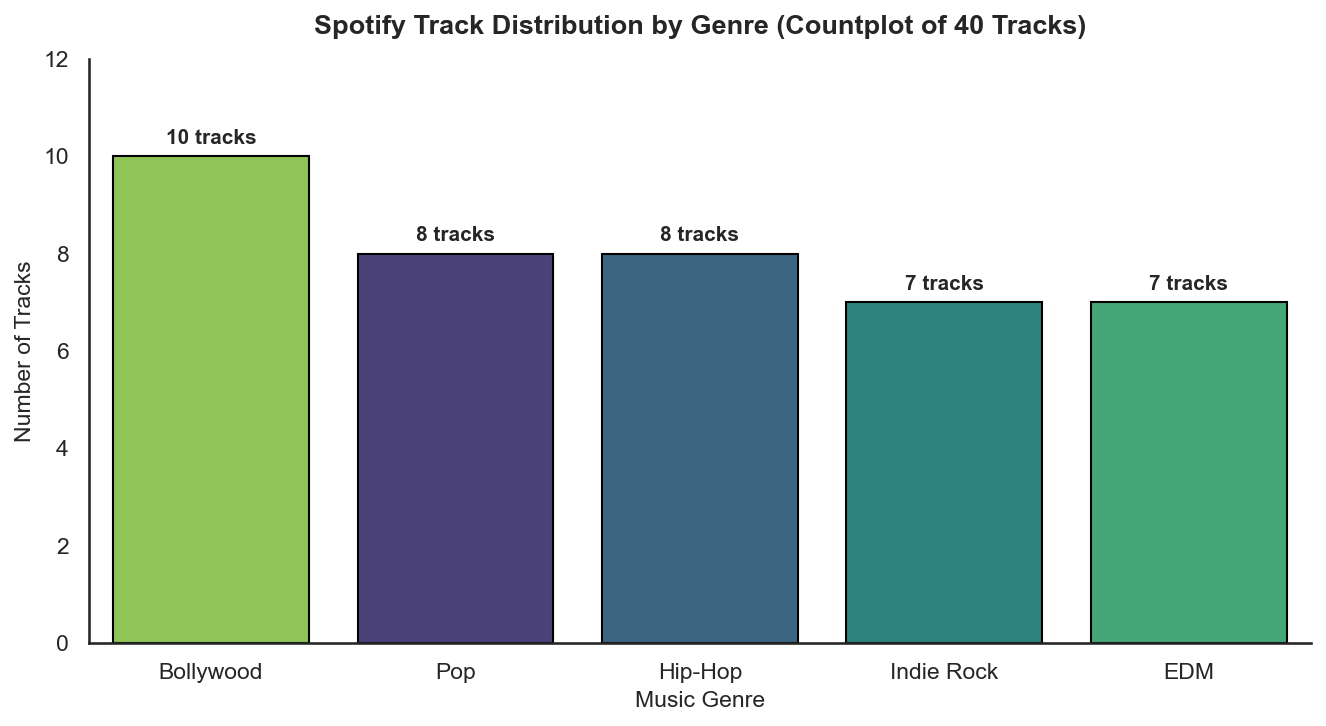

Genre Distribution Breakdown:
 - Bollywood: 10 tracks (25.0%)
 - Pop: 8 tracks (20.0%)
 - Hip-Hop: 8 tracks (20.0%)
 - Indie Rock: 7 tracks (17.5%)
 - EDM: 7 tracks (17.5%)


In [4]:
# Load Spotify tracks dataset
df_spotify = pd.read_csv("spotify_tracks_genres.csv")
print("--- 40 Spotify Tracks Dataset Sample ---")
display(df_spotify.head(10))
print(f"Total Tracks: {len(df_spotify)} across {df_spotify['genre'].nunique()} distinct genres")

# Count distribution per genre
genre_counts = df_spotify["genre"].value_counts().reset_index()
genre_counts.columns = ["genre", "track_count"]
display(genre_counts)

# Visualizing with sns.countplot
plt.figure(figsize=(9, 5), dpi=150)
sns.set_theme(style="white")

genre_order = df_spotify["genre"].value_counts().index

ax = sns.countplot(
    data=df_spotify,
    x="genre",
    hue="genre",
    order=genre_order,
    palette="viridis",
    edgecolor="black",
    legend=False
)

# Label exact counts directly above each bar
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(
        f"{height} tracks",
        (p.get_x() + p.get_width() / 2., height),
        ha="center", va="bottom",
        fontsize=10, fontweight="bold",
        xytext=(0, 4), textcoords="offset points"
    )

plt.title("Spotify Track Distribution by Genre (Countplot of 40 Tracks)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Music Genre", fontsize=11)
plt.ylabel("Number of Tracks", fontsize=11)
plt.ylim(0, 12)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig("spotify_genre_countplot.png", bbox_inches="tight")
plt.show()

print("Genre Distribution Breakdown:")
for g, c in df_spotify["genre"].value_counts().items():
    print(f" - {g}: {c} tracks ({c/len(df_spotify)*100:.1f}%)")


---
### Task 5: Daily Step Counts Density Distribution (KDE Plot - Whitegrid Theme)
**Problem Statement:**  
*Use Seaborn's `kdeplot` to visualize the distribution of daily step counts for a week, as if analyzing data from a fitness app. Apply the 'whitegrid' theme and customize the plot color.*


--- 7-Day Fitness Daily Step Records ---


,day,daily_total_steps
0,Monday,8216
1,Tuesday,9049
2,Wednesday,9187
3,Thursday,7807
4,Friday,11272
5,Saturday,13606
6,Sunday,10527



Weekly Step Statistics:


,count,mean,std,min,25%,50%,75%,max
daily_total_steps,7.0,9952.0,2018.254031,7807.0,8632.5,9187.0,10899.5,13606.0


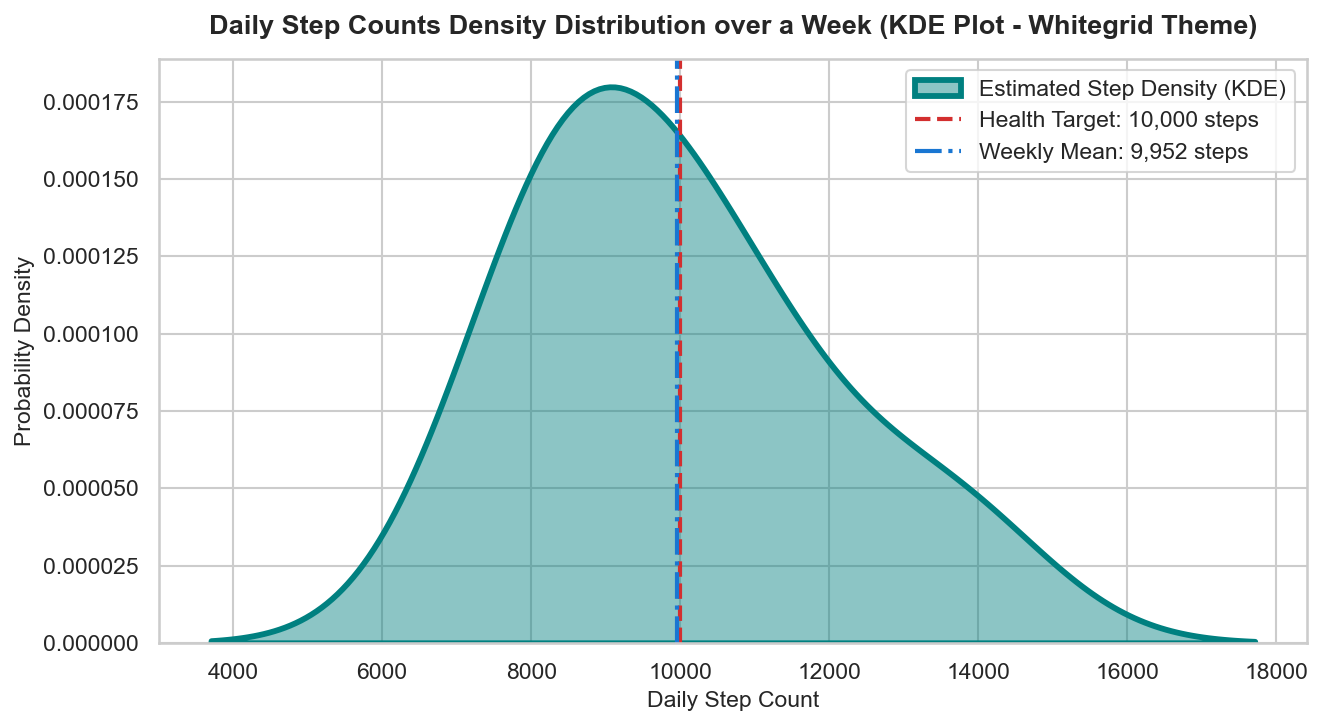

Average Steps Logged: 9,952 steps/day
Days Meeting 10,000 Step Goal: 3 / 7 days


In [5]:
# Load Fitness Tracker Steps Dataset
df_fitness = pd.read_csv("fitness_daily_steps.csv")
# Aggregate daily total steps across the 7 days of the week
df_daily_agg = df_fitness.groupby("day", sort=False)["daily_total_steps"].first().reset_index()

print("--- 7-Day Fitness Daily Step Records ---")
display(df_daily_agg)
print("\nWeekly Step Statistics:")
display(df_daily_agg["daily_total_steps"].describe().to_frame().T)

# Visualizing step count probability density with sns.kdeplot
plt.figure(figsize=(9, 5), dpi=150)
sns.set_theme(style="whitegrid")

ax = sns.kdeplot(
    data=df_daily_agg,
    x="daily_total_steps",
    fill=True,
    color="#008080", # Customized Teal Plot Color
    alpha=0.45,
    linewidth=2.8,
    label="Estimated Step Density (KDE)"
)

# Reference benchmark targets
target_steps = 10000
mean_steps = df_daily_agg["daily_total_steps"].mean()

plt.axvline(target_steps, color="#D32F2F", linestyle="--", linewidth=2, label=f"Health Target: {target_steps:,} steps")
plt.axvline(mean_steps, color="#1976D2", linestyle="-.", linewidth=2, label=f"Weekly Mean: {mean_steps:,.0f} steps")

plt.title("Daily Step Counts Density Distribution over a Week (KDE Plot - Whitegrid Theme)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Daily Step Count", fontsize=11)
plt.ylabel("Probability Density", fontsize=11)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig("daily_steps_kdeplot.png", bbox_inches="tight")
plt.show()

print(f"Average Steps Logged: {mean_steps:,.0f} steps/day")
print(f"Days Meeting 10,000 Step Goal: {(df_daily_agg['daily_total_steps'] >= 10000).sum()} / 7 days")


---
## 📌 Summary & Key Takeaways

1. **`histplot` vs `kdeplot`**:
   - `histplot` bins continuous measurements into discrete intervals, ideal for discrete counts like delivery times.
   - `kdeplot` computes Gaussian kernel densities, providing a smooth estimation of the underlying probability distribution.
2. **`boxplot` vs `violinplot`**:
   - `boxplot` explicitly highlights quartiles, medians, and Tukey outliers ($1.5 \times \text{IQR}$).
   - `violinplot` embeds internal boxplot quartiles while revealing bimodal or multimodal distribution contours across categories.
3. **`countplot`**:
   - Simplifies categorical frequency counting without requiring pre-aggregation with `groupby().count()`.
4. **Themes & Aesthetics**:
   - `sns.set_theme(style='darkgrid')` provides high-contrast grid lines for dense numeric distributions.
   - `sns.set_theme(style='whitegrid')` delivers clean presentation-ready figures with subtle horizontal guides.
